# Visualização — Water Treatment Plant (UCI)

Medições diárias de uma estação de tratamento de esgoto urbano (Poch, 1993).
527 dias, de janeiro de 1990 a outubro de 1991. O arquivo não vem em ordem cronológica. Cada linha é um dia; valor ausente no arquivo original é `?`.

O foco destes gráficos é o que interessa a um sensor virtual de carga orgânica:

- **DBO** — demanda biológica de oxigênio (BOD)
- **DQO** — demanda química de oxigênio (COD)
- **SS** — sólidos em suspensão (TSS)

Sufixos: **E** entrada da planta, **P** decantador primário, **D** decantador secundário, **S** saída.
As unidades não estão documentadas na UCI. Não há coluna de amônio (NH4+ / TAN).

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

%matplotlib inline

plt.rcParams.update({
    "figure.facecolor": "white",
    "axes.facecolor": "white",
    "axes.spines.top": False,
    "axes.spines.right": False,
    "axes.grid": True,
    "grid.color": "0.85",
    "grid.linewidth": 0.6,
    "font.size": 11,
    "axes.titlesize": 13,
    "axes.titleweight": "medium",
})

COR_ENTRADA = "#1f4e79"
COR_SAIDA = "#c45c26"
COR_PRIMARIO = "#1a7a6d"
COR_SECUNDARIO = "#5c4d9a"

COLUMNS = [
    "dia",
    "Q-E", "ZN-E", "PH-E", "DBO-E", "DQO-E", "SS-E", "SSV-E", "SED-E", "COND-E",
    "PH-P", "DBO-P", "SS-P", "SSV-P", "SED-P", "COND-P",
    "PH-D", "DBO-D", "DQO-D", "SS-D", "SSV-D", "SED-D", "COND-D",
    "PH-S", "DBO-S", "DQO-S", "SS-S", "SSV-S", "SED-S", "COND-S",
    "RD-DBO-P", "RD-SS-P", "RD-SED-P", "RD-DBO-S", "RD-DQO-S",
    "RD-DBO-G", "RD-DQO-G", "RD-SS-G", "RD-SED-G",
]

def localizar_dados() -> Path:
    relativos = [
        Path("data") / "water-treatment-plant" / "water-treatment.data",
        Path("..") / "data" / "water-treatment-plant" / "water-treatment.data",
    ]
    for caminho in relativos:
        if caminho.exists():
            return caminho
    raise FileNotFoundError(
        "Não encontrei water-treatment.data. Abra o notebook na pasta do projeto ou em notebooks/."
    )

df = pd.read_csv(localizar_dados(), header=None, names=COLUMNS, na_values="?")
df["data"] = pd.to_datetime(df["dia"].str.replace("D-", "", regex=False), format="%d/%m/%y")
df = df.sort_values("data").reset_index(drop=True)
df.head()

,dia,Q-E,ZN-E,PH-E,DBO-E,DQO-E,SS-E,SSV-E,SED-E,COND-E,...,RD-DBO-P,RD-SS-P,RD-SED-P,RD-DBO-S,RD-DQO-S,RD-DBO-G,RD-DQO-G,RD-SS-G,RD-SED-G,data
0,D-1/1/90,41230.0,0.35,7.6,120.0,344.0,136.0,54.4,4.5,993,...,NaN,62.8,93.3,NaN,62.5,86.7,71.8,87.5,99.4,1990-01-01
1,D-2/1/90,37386.0,1.40,7.9,165.0,470.0,170.0,76.5,4.0,1365,...,NaN,50.0,94.4,85.9,73.6,86.7,79.4,89.4,100.0,1990-01-02
2,D-3/1/90,34535.0,1.00,7.8,232.0,518.0,220.0,65.5,5.5,1617,...,32.6,62.4,95.0,81.3,59.9,87.5,71.8,85.9,99.8,1990-01-03
3,D-4/1/90,32527.0,3.00,7.8,187.0,460.0,180.0,67.8,5.2,1832,...,13.2,57.6,95.5,85.3,70.4,85.0,77.2,83.3,100.0,1990-01-04
4,D-7/1/90,27760.0,1.20,7.6,199.0,466.0,186.0,74.2,4.5,1220,...,38.2,46.6,95.0,84.9,61.1,89.4,73.8,86.6,99.6,1990-01-07


## Panorama

Quantos dias existem, qual o intervalo e quantos valores faltam nas variáveis do sensor.

In [2]:
numericas = [c for c in COLUMNS if c != "dia"]
faltantes = df[numericas].isna().sum()

print(f"Dias: {len(df)}")
print(f"Período: {df['data'].min():%d/%m/%Y} a {df['data'].max():%d/%m/%Y}")
print(f"Dias com as 38 medições completas: {df[numericas].dropna().shape[0]}")
print()

foco = [
    "DBO-E", "DBO-P", "DBO-D", "DBO-S",
    "DQO-E", "DQO-D", "DQO-S",
    "SS-E", "SS-P", "SS-D", "SS-S",
]
resumo = df[foco].agg(["count", "min", "median", "mean", "max"]).T
resumo.columns = ["n", "mínimo", "mediana", "média", "máximo"]
resumo["faltantes"] = faltantes[foco]
resumo.round(1)

Dias: 527
Período: 01/01/1990 a 30/10/1991
Dias com as 38 medições completas: 380



,n,mínimo,mediana,média,máximo,faltantes
DBO-E,504.0,31.0,182.5,188.7,438.0,23
DBO-P,487.0,32.0,197.0,206.2,517.0,40
DBO-D,499.0,26.0,119.0,122.3,285.0,28
DBO-S,504.0,3.0,18.0,20.0,320.0,23
DQO-E,521.0,81.0,400.0,406.9,941.0,6
DQO-D,518.0,80.0,274.0,274.0,511.0,9
DQO-S,509.0,9.0,84.0,87.3,350.0,18
SS-E,526.0,98.0,196.0,227.4,2008.0,1
SS-P,527.0,104.0,220.0,254.0,1692.0,0
SS-D,525.0,49.0,90.0,94.2,244.0,2


## Valores ausentes

Quase todos os atributos têm buracos. DBO e os índices de desempenho (`RD-*`) são os mais incompletos. A página da UCI marca o conjunto como sem faltantes; o arquivo usa `?`.

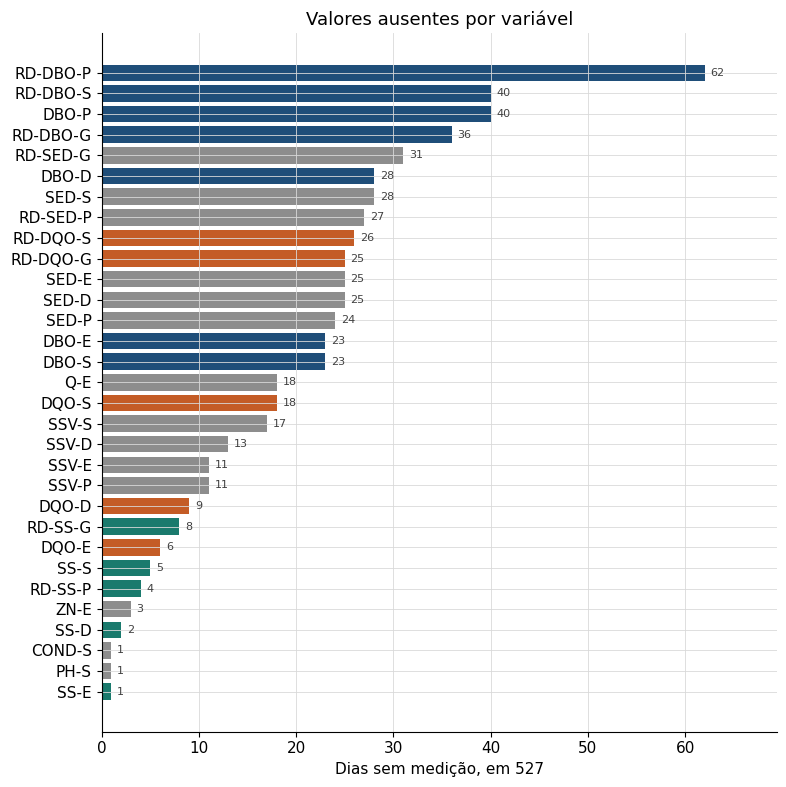

In [3]:
def cor_coluna(nome: str) -> str:
    if "DBO" in nome:
        return "#1f4e79"
    if "DQO" in nome:
        return "#c45c26"
    if nome.startswith("SS-") or nome.startswith("RD-SS"):
        return "#1a7a6d"
    return "#8d8d8d"

miss = faltantes[faltantes > 0].sort_values()
fig, ax = plt.subplots(figsize=(8, 8))
ax.barh(miss.index, miss.values, color=[cor_coluna(n) for n in miss.index])
ax.set_xlabel("Dias sem medição, em 527")
ax.set_title("Valores ausentes por variável")
ax.set_xlim(0, max(miss.max() * 1.12, 10))
for y, valor in enumerate(miss.values):
    ax.text(valor + 0.6, y, str(int(valor)), va="center", fontsize=8, color="0.25")
fig.tight_layout()

## Série temporal: entrada e saída

A saída (laranja) fica bem abaixo da entrada (azul) na maior parte do período. Os picos de DBO e de sólidos na saída, como março de 1990, são os dias em que a planta sai do regime normal.

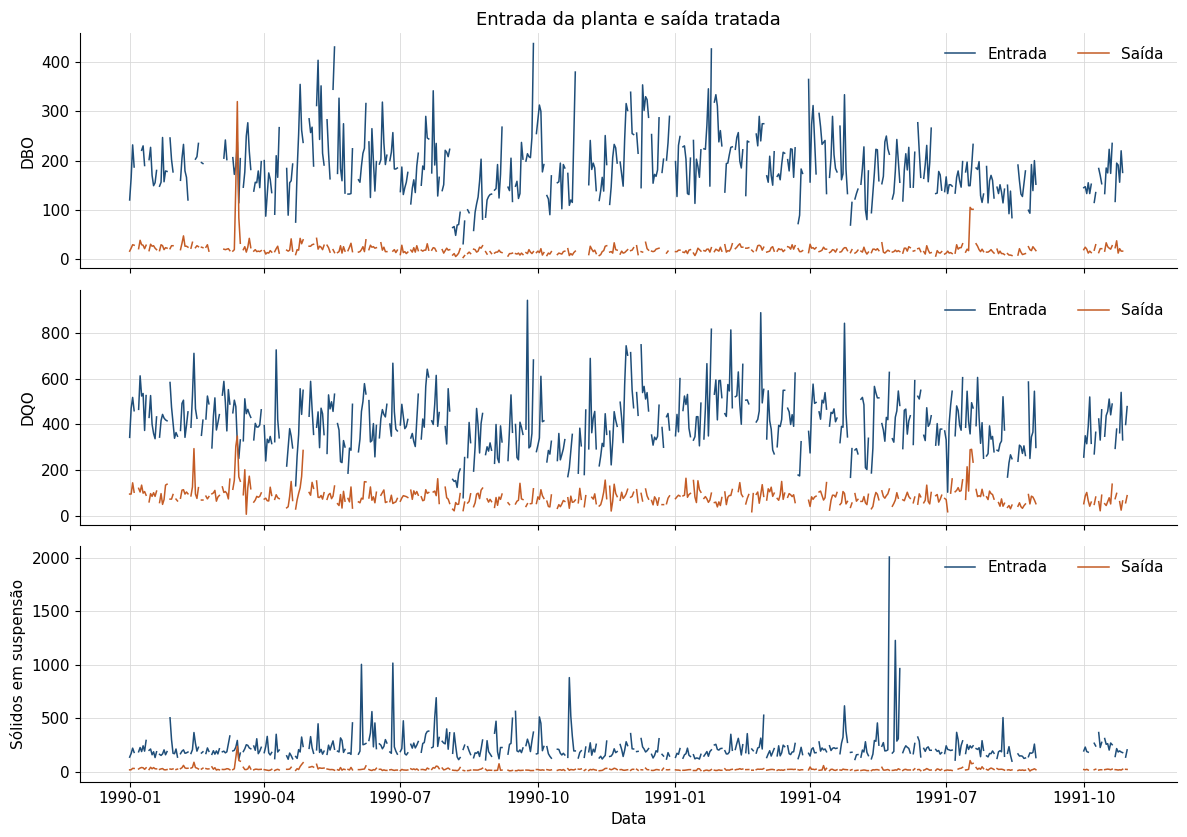

In [4]:
series = [
    ("DBO-E", "DBO-S", "DBO"),
    ("DQO-E", "DQO-S", "DQO"),
    ("SS-E", "SS-S", "Sólidos em suspensão"),
]

diario = df.set_index("data").sort_index().asfreq("D")

fig, axes = plt.subplots(3, 1, figsize=(12, 8.5), sharex=True)
for ax, (entrada, saida, titulo) in zip(axes, series):
    ax.plot(diario.index, diario[entrada], color=COR_ENTRADA, lw=1.1, label="Entrada")
    ax.plot(diario.index, diario[saida], color=COR_SAIDA, lw=1.1, label="Saída")
    ax.set_ylabel(titulo)
    ax.legend(loc="upper right", frameon=False, ncol=2)
axes[0].set_title("Entrada da planta e saída tratada")
axes[-1].set_xlabel("Data")
fig.tight_layout()

## Distribuição em cada etapa

DBO e sólidos caem ao longo do tratamento. DQO não foi medida na entrada do decantador primário, por isso esse estágio não aparece. A saída tem cauda longa: a mediana é baixa e alguns dias passam de 100.

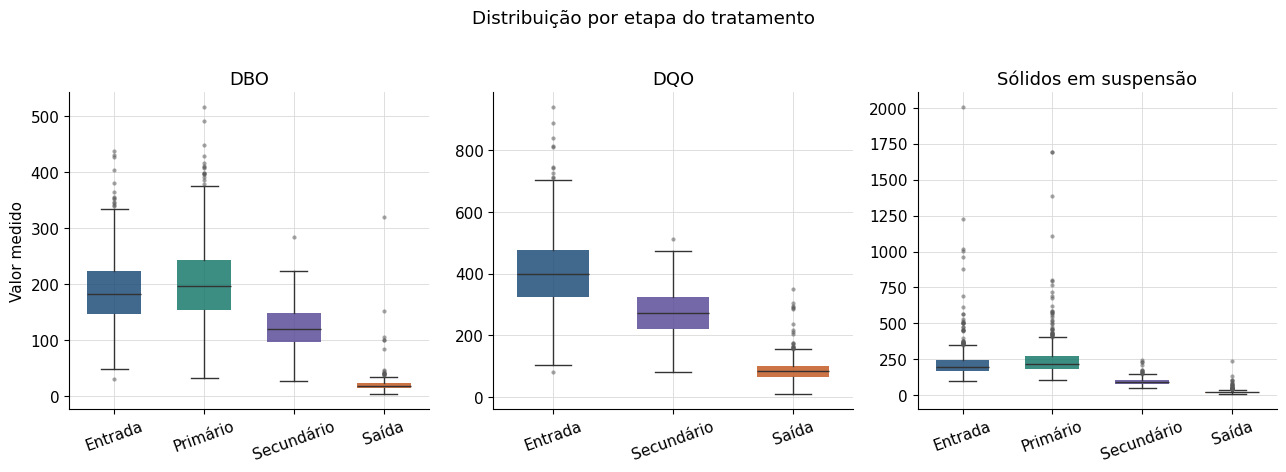

In [5]:
grupos = [
    ("DBO", ["DBO-E", "DBO-P", "DBO-D", "DBO-S"], ["Entrada", "Primário", "Secundário", "Saída"],
     [COR_ENTRADA, COR_PRIMARIO, COR_SECUNDARIO, COR_SAIDA]),
    ("DQO", ["DQO-E", "DQO-D", "DQO-S"], ["Entrada", "Secundário", "Saída"],
     [COR_ENTRADA, COR_SECUNDARIO, COR_SAIDA]),
    ("Sólidos em suspensão", ["SS-E", "SS-P", "SS-D", "SS-S"], ["Entrada", "Primário", "Secundário", "Saída"],
     [COR_ENTRADA, COR_PRIMARIO, COR_SECUNDARIO, COR_SAIDA]),
]

fig, axes = plt.subplots(1, 3, figsize=(13, 4.6))
for ax, (titulo, colunas, rotulos, cores) in zip(axes, grupos):
    dados = [df[c].dropna().to_numpy() for c in colunas]
    bp = ax.boxplot(
        dados, tick_labels=rotulos, patch_artist=True, widths=0.6,
        flierprops=dict(marker="o", markersize=3, markerfacecolor="0.35", markeredgecolor="none", alpha=0.55),
    )
    for caixa, cor in zip(bp["boxes"], cores):
        caixa.set_facecolor(cor)
        caixa.set_alpha(0.85)
        caixa.set_edgecolor("none")
    for item in ("whiskers", "caps", "medians"):
        for linha in bp[item]:
            linha.set_color("0.2")
    ax.set_title(titulo)
    ax.tick_params(axis="x", labelrotation=20)
axes[0].set_ylabel("Valor medido")
fig.suptitle("Distribuição por etapa do tratamento", y=1.02)
fig.tight_layout()

## Entrada contra saída

A linha tracejada é a igualdade: um ponto nela significa que a saída saiu igual à entrada. A cor é o tempo, do início da série (escuro) ao fim (claro). A nuvem abaixo da diagonal é a remoção. Os pontos altos no eixo da saída são falhas de tratamento, não o regime típico.

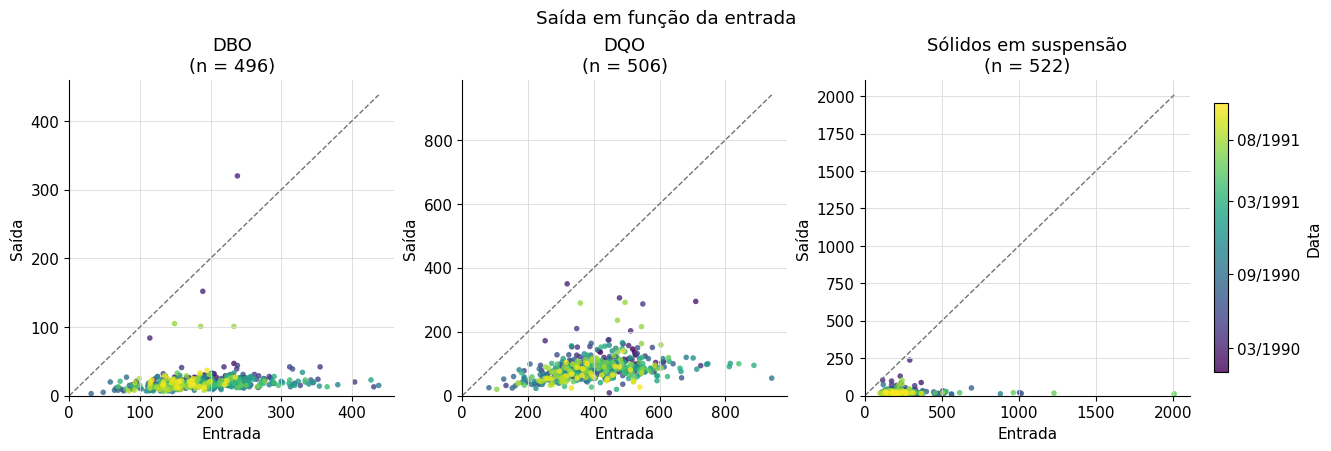

In [6]:
pares = [
    ("DBO-E", "DBO-S", "DBO"),
    ("DQO-E", "DQO-S", "DQO"),
    ("SS-E", "SS-S", "Sólidos em suspensão"),
]

fig, axes = plt.subplots(1, 3, figsize=(13.2, 4.4), layout="constrained")
dispersao = None
for ax, (x, y, titulo) in zip(axes, pares):
    sub = df[[x, y, "data"]].dropna()
    dispersao = ax.scatter(
        sub[x], sub[y],
        c=sub["data"].map(pd.Timestamp.toordinal),
        cmap="viridis",
        s=16,
        alpha=0.8,
        linewidths=0,
    )
    limite = float(np.nanmax([sub[x].max(), sub[y].max()]))
    ax.plot([0, limite], [0, limite], ls="--", color="0.45", lw=1)
    ax.set_xlim(0, None)
    ax.set_ylim(0, None)
    ax.set_xlabel("Entrada")
    ax.set_ylabel("Saída")
    ax.set_title(f"{titulo}\n(n = {len(sub)})")

barra = fig.colorbar(dispersao, ax=axes, shrink=0.85, pad=0.02)
marcas = pd.to_datetime(["1990-03-01", "1990-09-01", "1991-03-01", "1991-08-01"])
barra.set_ticks(marcas.map(pd.Timestamp.toordinal))
barra.set_ticklabels(marcas.strftime("%m/%Y"))
barra.set_label("Data")
fig.suptitle("Saída em função da entrada")

## Correlação

DBO, DQO e sólidos andam juntos na entrada e, em menor grau, na saída. Condutividade e pH quase não acompanham a DBO. Correlação de Pearson, calculada só nos dias em que o par está presente.

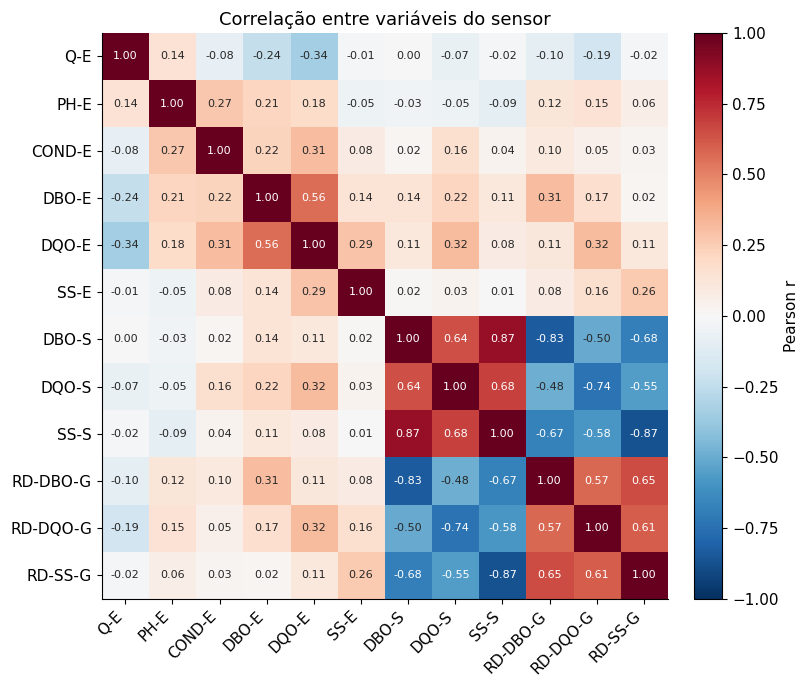

In [7]:
cols_corr = [
    "Q-E", "PH-E", "COND-E",
    "DBO-E", "DQO-E", "SS-E",
    "DBO-S", "DQO-S", "SS-S",
    "RD-DBO-G", "RD-DQO-G", "RD-SS-G",
]
corr = df[cols_corr].corr()

fig, ax = plt.subplots(figsize=(8.2, 7))
imagem = ax.imshow(corr, cmap="RdBu_r", vmin=-1, vmax=1)
ax.set_xticks(range(len(cols_corr)), cols_corr, rotation=45, ha="right")
ax.set_yticks(range(len(cols_corr)), cols_corr)
ax.grid(False)
for i in range(len(cols_corr)):
    for j in range(len(cols_corr)):
        valor = corr.iloc[i, j]
        ax.text(
            j, i, f"{valor:.2f}",
            ha="center", va="center", fontsize=8,
            color="white" if abs(valor) > 0.55 else "0.15",
        )
fig.colorbar(imagem, ax=ax, fraction=0.046, pad=0.04, label="Pearson r")
ax.set_title("Correlação entre variáveis do sensor")
fig.tight_layout()

## Desempenho informado pela planta

`RD-*-G` é o desempenho global, na escala aproximada de 0 a 100. DBO e sólidos ficam altos na maior parte dos dias; as quedas coincidem com os picos de saída vistos na série temporal.

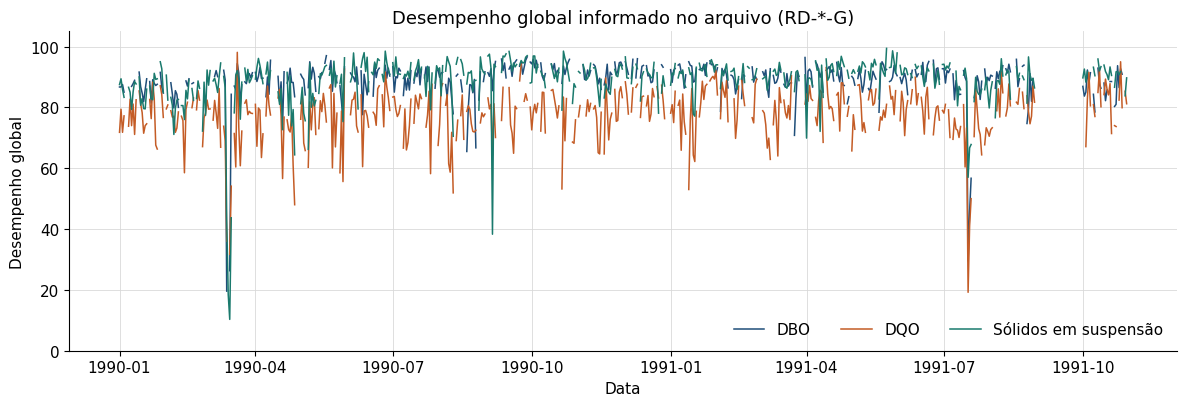

In [8]:
fig, ax = plt.subplots(figsize=(12, 4.2))
ax.plot(diario.index, diario["RD-DBO-G"], color=COR_ENTRADA, lw=1.1, label="DBO")
ax.plot(diario.index, diario["RD-DQO-G"], color=COR_SAIDA, lw=1.1, label="DQO")
ax.plot(diario.index, diario["RD-SS-G"], color=COR_PRIMARIO, lw=1.1, label="Sólidos em suspensão")
ax.set_ylim(0, 105)
ax.set_ylabel("Desempenho global")
ax.set_xlabel("Data")
ax.set_title("Desempenho global informado no arquivo (RD-*-G)")
ax.legend(loc="lower right", frameon=False, ncol=3)
fig.tight_layout()